# Segmentación de inmuebles en arriendo con algoritmos no supervisados — Parte 1
### K-Means: descubrir segmentos de inmuebles sin etiquetas

---

**Universidad de Cundinamarca** — Esp. Inteligencia Artificial

**CADI:** Introducción a Machine Learning · Período 2026-2

**Estudiante:** Ruby Dayana Cárdenas Gómez

**Docente:** Ing. Wilson Rojas Reales, PhD(c)

**Repositorio GitHub:** `https://github.com/RubyDayana/ml-no-supervisado-inmuebles.git`

---

### ¿Qué se hace en este notebook?

Una inmobiliaria administra un portafolio de inmuebles en arriendo y **no tiene una clasificación previa** de
sus propiedades. Quiere saber si existen grupos naturales según sus características físicas, económicas y
geográficas, para diseñar estrategias comerciales distintas. Este notebook responde la parte de **K-Means** de la
actividad (la parte de PCA está en el notebook 2, y SVD y clustering jerárquico en el 3).

Lo que se hace, en orden:

1. **Auditar el dataset** del docente (1 000 inmuebles). Aparecen dos hallazgos que hay que resolver antes de
   agrupar: una columna `Estrato` duplicada y un encabezado con error.
2. **Ejecutar el ejercicio de ejemplo** `KMeansSegInmuebles.py` (12 inmuebles) para ver cómo se ve un resultado
   esperado: económicos, intermedios y premium.
3. **Modificar el script** para que lea el Excel de 1 000 inmuebles y generar los resultados (actividad 2).
4. Comprobar **por qué hay que escalar** los datos: el precio de arriendo domina la distancia.
5. Cambiar los parámetros del modelo a `n_clusters=2` y `n_clusters=4` (actividad 3) y decidir cuál número de
   clusters es más útil, con el método del codo y el índice de silueta.
6. Describir cada segmento y proponer una **estrategia comercial**.
7. **Responder las 11 preguntas** del enunciado.

### Glosario rápido

| Término | Qué significa aquí |
|---|---|
| **Aprendizaje no supervisado** | El algoritmo no recibe una columna "respuesta"; busca estructura en los datos por sí solo. |
| **Clustering** | Agrupar observaciones parecidas entre sí y distintas de las de otros grupos. |
| **K-Means** | Algoritmo de clustering que reparte los datos en *k* grupos, cada uno representado por su **centroide** (el promedio de sus miembros). |
| **Centroide** | Punto promedio de un grupo: el "inmueble típico" del segmento. |
| **Inercia** | Suma de las distancias al cuadrado de cada inmueble a su centroide. Mide qué tan compactos son los grupos (menor es más compacto). |
| **Silueta** | Entre −1 y 1: qué tan bien encaja cada inmueble en su grupo frente al grupo vecino. Cerca de 1, grupos bien separados. |

---
## 1. El dataset del docente

El archivo `DATASET_Inmuebles.xlsx` trae el **identificador** del inmueble y sus características. El enunciado pide
conservar el identificador para reconocer los registros, **pero no usarlo como característica** al calcular
distancias: es solo una etiqueta, no describe al inmueble.

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
SEMILLA = 42

URL_DATOS = ("https://raw.githubusercontent.com/RubyDayana/ml-no-supervisado-inmuebles/"
             "main/datos/DATASET_Inmuebles.xlsx")
RUTA = "datos/DATASET_Inmuebles.xlsx"

# Nombres limpios para las 10 columnas del Excel (el encabezado original trae un error de digitación
# en "Antigüedad" y la columna "Estrato" aparece dos veces).
NOMBRES = ["Inmueble", "Area_m2", "Habitaciones", "Estrato", "Precio_arriendo", "Banos",
           "Antiguedad_anios", "Localidad", "Tipo_inmueble", "Estrato_2"]


def cargar_crudo():
    """Lee el Excel del docente. Si no está en la carpeta datos/ (por ejemplo en Colab), lo descarga del repositorio."""
    if not os.path.exists(RUTA):
        os.makedirs("datos", exist_ok=True)
        urllib.request.urlretrieve(URL_DATOS, RUTA)
    return pd.read_excel(RUTA)

crudo = cargar_crudo()

print("Forma (filas, columnas):", crudo.shape)
print("Columnas tal como vienen en el Excel:")
print(list(crudo.columns))
print()
print("Valores nulos     :", int(crudo.isna().sum().sum()))
print("Filas duplicadas  :", int(crudo.duplicated().sum()))
print("IDs únicos        :", crudo["Inmueble"].is_unique)
crudo.head()

Forma (filas, columnas): (1000, 10)
Columnas tal como vienen en el Excel:
['Inmueble', 'Área m²', 'Habitaciones', 'Estrato', 'Precio arriendo', 'Baños', 'Antig[uedad', 'Localidad', 'Tipo Inmueble', 'Estrato.1']

Valores nulos     : 0
Filas duplicadas  : 0
IDs únicos        : True


,Inmueble,Área m²,Habitaciones,Estrato,Precio arriendo,Baños,Antig[uedad,Localidad,Tipo Inmueble,Estrato.1
0,I1,69,2,2,1413951,2,11,Suba,Apto,2
1,I2,39,1,2,1006165,2,10,Chapinero,Casa,3
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio,4
3,I4,62,3,4,3678698,1,12,Suba,Apto,3
4,I5,58,1,3,875729,1,12,Chapinero,Casa,4


### 1.1. Dos problemas en el archivo

1. El encabezado de la antigüedad dice `Antig[uedad` (un corchete en lugar de la *ü*).
2. La columna `Estrato` aparece **dos veces** (columnas D y J) y con valores distintos.

Lo primero es solo ortografía: renombro las columnas. Lo segundo necesita investigarse, porque si las dos
columnas fueran dos medidas reales del mismo atributo habría que decidir cuál usar. Comparo las dos contra el
precio de arriendo y entre sí.

In [2]:
assert len(crudo.columns) == len(NOMBRES), "El Excel debería tener 10 columnas"
df = crudo.copy()
df.columns = NOMBRES

print("Estrato   (columna D): valores", sorted(df["Estrato"].unique()))
print("Estrato_2 (columna J): valores", sorted(df["Estrato_2"].unique()))
print()
print("Correlación con el precio de arriendo:")
print(df[["Estrato", "Estrato_2"]].corrwith(df["Precio_arriendo"]).round(3).to_string())

coincide = (df["Estrato"] == df["Estrato_2"]).mean()
p1 = df["Estrato"].value_counts(normalize=True)
p2 = df["Estrato_2"].value_counts(normalize=True)
por_azar = float((p1 * p2).dropna().sum())
print()
print(f"Filas donde las dos columnas coinciden: {coincide * 100:.1f} %")
print(f"Coincidencia esperada si fueran independientes: {por_azar * 100:.1f} %")
print()
print("Tabla cruzada (filas = Estrato, columnas = Estrato_2):")
print(pd.crosstab(df["Estrato"], df["Estrato_2"]))

Estrato   (columna D): valores [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Estrato_2 (columna J): valores [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Correlación con el precio de arriendo:
Estrato      0.838
Estrato_2    0.025

Filas donde las dos columnas coinciden: 16.7 %
Coincidencia esperada si fueran independientes: 15.3 %

Tabla cruzada (filas = Estrato, columnas = Estrato_2):
Estrato_2   1   2   3   4
Estrato                  
2          55  55  57  42
3          58  52  57  43
4          45  50  49  55
5          45  44  51  41
6          55  42  47  57


**Decisión.** `Estrato` (columna D) va de 2 a 6, que es el rango de estratos residenciales que aparece en el
ejemplo del docente, y se relaciona fuertemente con el precio. `Estrato_2` (columna J) va solo de 1 a 4, no se
relaciona con el precio ni con nada, y coincide con `Estrato` casi exactamente lo que se esperaría por puro azar.
Es decir, no aporta información: la trato como una **columna espuria** y la descarto. Uso `Estrato`. (Conviene
confirmar con el docente cuál era la intención, pero esta es la lectura que soportan los datos.)

In [3]:
df = df.drop(columns="Estrato_2")

print("Columnas de trabajo:", list(df.columns))
print()
df[["Area_m2", "Habitaciones", "Estrato", "Precio_arriendo", "Banos", "Antiguedad_anios"]].describe().round(1)

Columnas de trabajo: ['Inmueble', 'Area_m2', 'Habitaciones', 'Estrato', 'Precio_arriendo', 'Banos', 'Antiguedad_anios', 'Localidad', 'Tipo_inmueble']



,Area_m2,Habitaciones,Estrato,Precio_arriendo,Banos,Antiguedad_anios
count,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
mean,96.7,2.7,4.0,3633286.7,1.5,8.5
std,54.1,1.3,1.4,2438534.3,0.5,2.3
min,30.0,1.0,2.0,702480.0,1.0,5.0
25%,55.0,2.0,3.0,1644060.2,1.0,6.0
50%,80.5,2.0,4.0,2930804.5,1.0,8.5
75%,135.0,4.0,5.0,5394807.0,2.0,10.0
max,220.0,5.0,6.0,8988836.0,2.0,12.0


### 1.2. Cómo se ven los datos

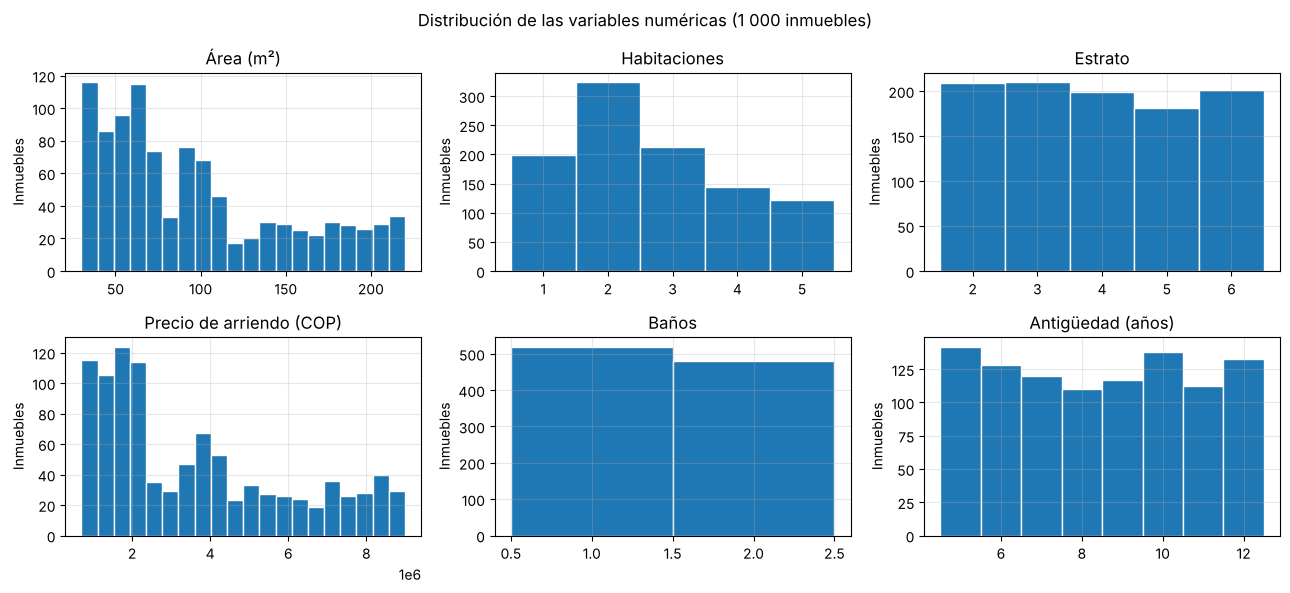

In [4]:
numericas = ["Area_m2", "Habitaciones", "Estrato", "Precio_arriendo", "Banos", "Antiguedad_anios"]
titulos = ["Área (m²)", "Habitaciones", "Estrato", "Precio de arriendo (COP)", "Baños", "Antigüedad (años)"]

fig, ejes = plt.subplots(2, 3, figsize=(13, 6))
for eje, col, titulo in zip(ejes.ravel(), numericas, titulos):
    eje.hist(df[col], bins=20 if df[col].nunique() > 8 else np.arange(df[col].min() - 0.5, df[col].max() + 1.5),
             color="tab:blue", edgecolor="white")
    eje.set(title=titulo, ylabel="Inmuebles")
plt.suptitle("Distribución de las variables numéricas (1 000 inmuebles)")
plt.tight_layout(); plt.show()

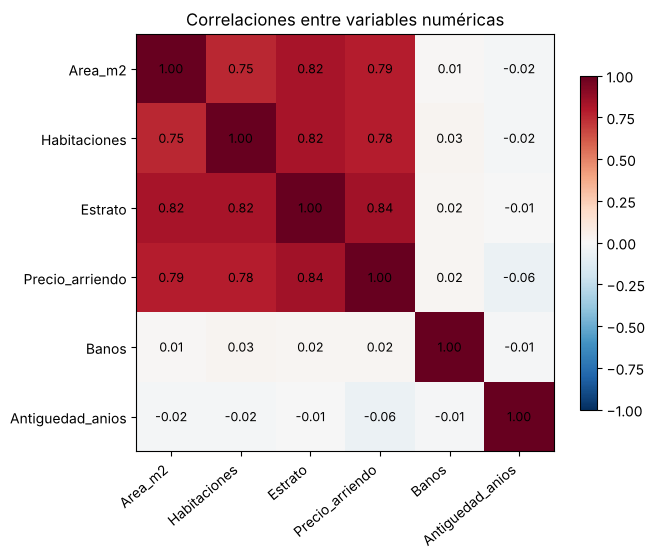

In [5]:
corr = df[numericas].corr()
fig, eje = plt.subplots(figsize=(6.8, 5.6))
im = eje.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
eje.set_xticks(range(len(numericas)), labels=numericas, rotation=40, ha="right")
eje.set_yticks(range(len(numericas)), labels=numericas)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        eje.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
eje.grid(False)
plt.colorbar(im, shrink=0.8); plt.title("Correlaciones entre variables numéricas")
plt.tight_layout(); plt.show()

In [6]:
print("Inmuebles por localidad y por tipo:")
print(df["Localidad"].value_counts().to_string())
print()
print(df["Tipo_inmueble"].value_counts().to_string())
print()
print("Precio promedio de arriendo según localidad y según tipo (COP):")
print(df.groupby("Localidad")["Precio_arriendo"].mean().round(0).to_string())
print()
print(df.groupby("Tipo_inmueble")["Precio_arriendo"].mean().round(0).to_string())

Inmuebles por localidad y por tipo:
Localidad
Suba         334
Chapinero    333
Usaquén      333

Tipo_inmueble
Apto             334
Casa             333
ApartaEstudio    333

Precio promedio de arriendo según localidad y según tipo (COP):
Localidad
Chapinero    3537593.0
Suba         3370336.0
Usaquén      3992720.0

Tipo_inmueble
ApartaEstudio    3992720.0
Apto             3370336.0
Casa             3537593.0


In [7]:
print("Cruce Localidad x Tipo de inmueble:")
print(pd.crosstab(df["Localidad"], df["Tipo_inmueble"]))

Cruce Localidad x Tipo de inmueble:
Tipo_inmueble  ApartaEstudio  Apto  Casa
Localidad                               
Chapinero                  0     0   333
Suba                       0   334     0
Usaquén                  333     0     0


**Qué se observa.**

- **Las cuatro variables de "tamaño y valor" se repiten entre sí.** Área, habitaciones, estrato y precio se
  correlacionan entre 0.75 y 0.84: un inmueble grande suele tener más habitaciones, estrato más alto y arriendo
  más caro. Describen, en esencia, una sola dimensión (qué tan grande y valioso es el inmueble).
- **Baños y antigüedad no se relacionan con nada.** Sus correlaciones con las demás variables están entre −0.06 y
  0.03; el precio promedio es casi igual con uno o dos baños (3.60 vs. 3.67 millones).
- **Localidad y tipo de inmueble son la misma información.** El cruce muestra una correspondencia perfecta:
  todo lo que está en Chapinero es casa, todo lo de Suba es apartamento y todo lo de Usaquén es apartaestudio.
  Por eso sus promedios de precio coinciden exactamente. Incluir las dos variables en un modelo sería contar dos
  veces lo mismo; en este trabajo uso solo `Localidad`, como hace el script del docente.

---
## 2. El ejercicio de ejemplo del docente: `KMeansSegInmuebles.py`

Antes de usar el dataset grande ejecuto el script del docente tal cual, con sus 12 inmuebles, para ver el
resultado esperado: **económicos**, **intermedios** y **premium**. La lógica es la del script original (se
agregan solo un par de impresiones para mostrar el tamaño de cada grupo).

In [8]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

data = {
    "Inmueble": ["I1", "I2", "I3", "I4", "I5", "I6", "I7", "I8", "I9", "I10", "I11", "I12"],
    "area_m2": [45, 50, 60, 85, 90, 120, 130, 40, 55, 100, 150, 35],
    "habitaciones": [1, 2, 2, 3, 3, 4, 4, 1, 2, 3, 4, 1],
    "estrato": [3, 3, 4, 4, 5, 5, 6, 2, 3, 5, 6, 2],
    "precio_arriendo": [1200000, 1400000, 1800000, 2600000, 3200000, 4500000,
                        5500000, 900000, 1500000, 3700000, 7000000, 800000],
}
df_ej = pd.DataFrame(data)

X_ej = df_ej[["area_m2", "habitaciones", "estrato", "precio_arriendo"]]
scaler_ej = StandardScaler()
X_ej_esc = scaler_ej.fit_transform(X_ej)

modelo_ej = KMeans(n_clusters=3, random_state=42, n_init=10)
modelo_ej.fit(X_ej_esc)
df_ej["cluster"] = modelo_ej.labels_

print("Inmuebles asignados a cada cluster:")
print(df_ej.sort_values(["cluster", "precio_arriendo"]).to_string(index=False))
print()
print("Resumen promedio por cluster (escala original):")
print(df_ej.groupby("cluster")[["area_m2", "habitaciones", "estrato", "precio_arriendo"]].mean().round(1))

Inmuebles asignados a cada cluster:
Inmueble  area_m2  habitaciones  estrato  precio_arriendo  cluster
      I4       85             3        4          2600000        0
      I5       90             3        5          3200000        0
     I10      100             3        5          3700000        0
     I12       35             1        2           800000        1
      I8       40             1        2           900000        1
      I1       45             1        3          1200000        1
      I2       50             2        3          1400000        1
      I9       55             2        3          1500000        1
      I3       60             2        4          1800000        1
      I6      120             4        5          4500000        2
      I7      130             4        6          5500000        2
     I11      150             4        6          7000000        2

Resumen promedio por cluster (escala original):
         area_m2  habitaciones  estrato  pre

El resultado coincide con la descripción del enunciado, con tres segmentos claramente distintos:

| Segmento | Inmuebles | Área | Habitaciones | Estrato | Arriendo promedio |
|---|---|---|---|---|---|
| **Económicos** | 6 (I1, I2, I3, I8, I9, I12) | 35–60 m² (47.5 en promedio) | 1.5 | 2.8 | 1 266 667 |
| **Intermedios** | 3 (I4, I5, I10) | 85–100 m² (91.7) | 3.0 | 4.7 | 3 166 667 |
| **Premium** | 3 (I6, I7, I11) | 120–150 m² (133.3) | 4.0 | 5.7 | 5 666 667 |

Un detalle práctico: en esta ejecución los números salieron como 1 = económicos, 0 = intermedios y 2 = premium,
mientras que el enunciado los numera 0, 1 y 2 de menor a mayor. **K-Means numera los grupos de forma
arbitraria** (depende de los centroides iniciales y de la versión de la librería); lo que tiene significado es
el perfil de cada grupo, no su número. Por eso, con el dataset grande, renumero los clusters por precio.

---
## 3. Modificar el script para leer el dataset de 1 000 inmuebles

Los cambios respecto al ejemplo son tres: en lugar de crear un `DataFrame` a mano se lee el Excel, el
identificador `Inmueble` se **conserva pero no entra** en las variables del modelo, y se agrupa por las mismas
cuatro variables del ejemplo: área, habitaciones, estrato y precio.

Como K-Means trabaja con distancias, antes hay que **escalar** (`StandardScaler`): cada variable se transforma a
media 0 y desviación 1, para que el precio, que vale millones, no aplaste al resto.

Una dificultad práctica: K-Means numera los grupos al azar (el "cluster 0" de una ejecución puede ser el "2" de
otra). Para que los resultados se puedan leer y comparar, **renumero los grupos de menor a mayor precio
promedio**: el cluster 0 siempre es el más económico.

In [9]:
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

VARIABLES = ["Area_m2", "Habitaciones", "Estrato", "Precio_arriendo"]
X = df[VARIABLES]                    # "Inmueble" (el ID) NO está aquí: no se usa para calcular distancias

scaler = StandardScaler()
X_esc = scaler.fit_transform(X)


def ordenar_por_precio(etiquetas, precios):
    """Renumera los clusters para que 0 sea el de menor precio promedio, 1 el siguiente, etc."""
    orden = pd.Series(precios).groupby(etiquetas).mean().sort_values().index
    mapa = {viejo: nuevo for nuevo, viejo in enumerate(orden)}
    return np.array([mapa[e] for e in etiquetas])


def ajustar_kmeans(k, datos=X_esc):
    """K-Means con los parámetros del enunciado; devuelve (modelo, etiquetas ordenadas por precio)."""
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10).fit(datos)
    return modelo, ordenar_por_precio(modelo.labels_, df["Precio_arriendo"].values)


modelo3, df["cluster"] = ajustar_kmeans(3)

print("Inmuebles por cluster:")
print(df["cluster"].value_counts().sort_index().to_string())
print()
df[["Inmueble"] + VARIABLES + ["cluster"]].head(8)

Inmuebles por cluster:
cluster
0    419
1    209
2    372



,Inmueble,Area_m2,Habitaciones,Estrato,Precio_arriendo,cluster
0,I1,69,2,2,1413951,0
1,I2,39,1,2,1006165,0
2,I3,142,5,5,8570904,2
3,I4,62,3,4,3678698,1
4,I5,58,1,3,875729,0
5,I6,76,3,4,2836207,1
6,I7,80,2,4,3808969,1
7,I8,204,4,6,8338969,2


### 3.1. Los centroides

Los centroides del modelo están en la escala estandarizada, que no se puede interpretar a simple vista. Se
devuelven a la escala original con `inverse_transform`, igual que en el script del docente. Un centroide es, por
definición, el promedio de sus miembros; lo compruebo comparándolo con el promedio directo de cada grupo.

In [10]:
centroides = pd.DataFrame(scaler.inverse_transform(modelo3.cluster_centers_), columns=VARIABLES)
centroides.index.name = "cluster (sin ordenar)"
print("Centroides en escala original (numeración interna de K-Means):")
print(centroides.round(1))

# Comprobación: centroide = promedio de los miembros del grupo
promedios = X.groupby(modelo3.labels_).mean()
print()
print("Diferencia máxima entre centroide y promedio del grupo:",
      float(np.abs(centroides.values - promedios.values).max()))

Centroides en escala original (numeración interna de K-Means):
                       Area_m2  Habitaciones  Estrato  Precio_arriendo
cluster (sin ordenar)                                                 
0                         49.7           1.5      2.5        1469201.9
1                        156.1           4.0      5.5        6353200.0
2                         85.4           2.5      4.1        3130625.3

Diferencia máxima entre centroide y promedio del grupo: 9.313225746154785e-10


In [11]:
df["Precio_m2"] = df["Precio_arriendo"] / df["Area_m2"]     # solo para interpretar; no se usó en el modelo

def perfil(etiqueta="cluster"):
    """Tamaño y promedio de cada variable por cluster (escala original)."""
    t = df.groupby(etiqueta).agg(
        Inmuebles=("Inmueble", "count"),
        Area_m2=("Area_m2", "mean"),
        Habitaciones=("Habitaciones", "mean"),
        Estrato=("Estrato", "mean"),
        Precio_arriendo=("Precio_arriendo", "mean"),
        Precio_por_m2=("Precio_m2", "mean"),
    )
    t.insert(1, "Porcentaje", (t["Inmuebles"] / len(df) * 100).round(1))
    return t.round(1)

print("Perfil de los 3 clusters (0 = más económico):")
perfil()

Perfil de los 3 clusters (0 = más económico):


,Inmuebles,Porcentaje,Area_m2,Habitaciones,Estrato,Precio_arriendo,Precio_por_m2
cluster,,,,,,,
0,419,41.9,49.7,1.5,2.5,1469201.9,31406.4
1,209,20.9,85.4,2.5,4.1,3130625.3,37694.7
2,372,37.2,156.1,4.0,5.5,6353200.0,43607.7


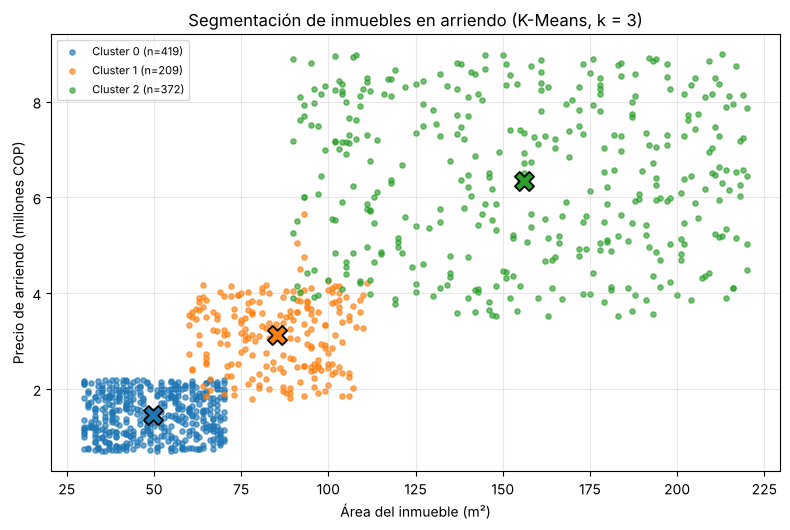

In [12]:
COLORES = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

def graficar_clusters(eje, etiquetas, k, titulo):
    """Dispersión área vs. precio coloreada por cluster, con los centroides marcados con X."""
    for c in range(k):
        m = etiquetas == c
        eje.scatter(df.loc[m, "Area_m2"], df.loc[m, "Precio_arriendo"] / 1e6, s=14, alpha=0.65,
                    color=COLORES[c], label=f"Cluster {c} (n={m.sum()})")
        eje.scatter(df.loc[m, "Area_m2"].mean(), df.loc[m, "Precio_arriendo"].mean() / 1e6, marker="X", s=190,
                    color=COLORES[c], edgecolor="black", linewidth=1.3, zorder=5)
    eje.set(xlabel="Área del inmueble (m²)", ylabel="Precio de arriendo (millones COP)", title=titulo)
    eje.legend(fontsize=8)

fig, eje = plt.subplots(figsize=(8, 5.4))
graficar_clusters(eje, df["cluster"].values, 3, "Segmentación de inmuebles en arriendo (K-Means, k = 3)")
plt.tight_layout(); plt.show()

Con los 1 000 inmuebles aparecen los mismos tres segmentos del ejemplo, pero ahora con una estructura más
rica. En la gráfica se ve un **bloque compacto de inmuebles pequeños y baratos** (menos de 70 m² y menos de
2.2 millones), un **bloque intermedio** (entre 70 y 110 m² y entre 2 y 4.2 millones) y una **región premium
amplia** que se extiende desde unos 90 m² y 3.5 millones hacia arriba y a la derecha. Los centroides (las X) son
los inmuebles típicos de cada segmento:

| Segmento | Inmuebles | % | Área | Habitaciones | Estrato | Arriendo promedio | COP por m² |
|---|---|---|---|---|---|---|---|
| **0 — Económico** | 419 | 41.9 % | 49.7 m² | 1.5 | 2.5 | 1 469 202 | 31 406 |
| **1 — Intermedio** | 209 | 20.9 % | 85.4 m² | 2.5 | 4.1 | 3 130 625 | 37 695 |
| **2 — Premium** | 372 | 37.2 % | 156.1 m² | 4.0 | 5.5 | 6 353 200 | 43 608 |

El precio por metro cuadrado sube de un segmento a otro (31 mil, 38 mil, 44 mil): además de ser más grandes, los
inmuebles premium son más caros por cada metro.

---
## 4. ¿Por qué el precio puede influir tanto en el resultado?

La distancia entre dos inmuebles se calcula sumando las diferencias al cuadrado de **todas** las variables. El
área difiere en decenas de m², las habitaciones en una o dos unidades, el estrato en un par de niveles... y el
precio en **millones de pesos**. Sin escalar, el precio es prácticamente la única variable que K-Means "ve".

Lo compruebo de dos maneras: midiendo cuánto pesa cada variable en la varianza total y comparando los grupos sin
escalar contra los grupos obtenidos **mirando solo el precio**.

In [13]:
print("Desviación estándar de cada variable (escala original):")
print(X.std().round(1).to_string())
print()
print("Porcentaje de la varianza total que aporta cada variable SIN escalar:")
print((X.var() / X.var().sum() * 100).round(4).to_string())
print()
print("Y después de escalar, cada variable aporta lo mismo:")
print((pd.DataFrame(X_esc, columns=VARIABLES).var() / 4 * 100).round(1).to_string())

Desviación estándar de cada variable (escala original):
Area_m2                 54.1
Habitaciones             1.3
Estrato                  1.4
Precio_arriendo    2438534.3

Porcentaje de la varianza total que aporta cada variable SIN escalar:
Area_m2              0.0
Habitaciones         0.0
Estrato              0.0
Precio_arriendo    100.0

Y después de escalar, cada variable aporta lo mismo:
Area_m2            25.0
Habitaciones       25.0
Estrato            25.0
Precio_arriendo    25.0


In [14]:
etiq_sin_escalar = ordenar_por_precio(KMeans(3, random_state=42, n_init=10).fit_predict(X.values), df["Precio_arriendo"].values)
etiq_solo_precio = ordenar_por_precio(KMeans(3, random_state=42, n_init=10).fit_predict(df[["Precio_arriendo"]]), df["Precio_arriendo"].values)
etiq_escalado = df["cluster"].values

print("Índice de Rand ajustado (ARI): 1 = agrupaciones idénticas, 0 = coincidencia por azar")
print(f"  Sin escalar  vs. agrupar SOLO por precio : {adjusted_rand_score(etiq_sin_escalar, etiq_solo_precio):.3f}")
print(f"  Escalado     vs. agrupar SOLO por precio : {adjusted_rand_score(etiq_escalado, etiq_solo_precio):.3f}")
print(f"  Sin escalar  vs. escalado                : {adjusted_rand_score(etiq_sin_escalar, etiq_escalado):.3f}")
print()
print(f"Inmuebles que cambian de grupo al escalar: {(etiq_sin_escalar != etiq_escalado).sum()} de {len(df)}")
print()
print("Tamaño de los grupos  (0, 1, 2):")
print("  sin escalar:", np.bincount(etiq_sin_escalar).tolist(), "   escalado:", np.bincount(etiq_escalado).tolist())

Índice de Rand ajustado (ARI): 1 = agrupaciones idénticas, 0 = coincidencia por azar
  Sin escalar  vs. agrupar SOLO por precio : 1.000
  Escalado     vs. agrupar SOLO por precio : 0.586
  Sin escalar  vs. escalado                : 0.586

Inmuebles que cambian de grupo al escalar: 228 de 1000

Tamaño de los grupos  (0, 1, 2):
  sin escalar: [498, 279, 223]    escalado: [419, 209, 372]


**Resultado.** Sin escalar, el precio aporta el **100 %** de la varianza total (su desviación estándar es de
2.4 millones, frente a 54 del área y 1.3 de habitaciones y estrato). Y la prueba definitiva: los grupos sin
escalar son **idénticos** a los que se obtienen agrupando *solo* por precio (ARI = 1.000). Las otras tres
variables no influyeron en absoluto, y 228 de los 1 000 inmuebles (22.8 %) terminan en un grupo distinto al
escalar. Después de escalar, cada variable aporta el 25 %.

Una precisión importante: aun con los datos escalados, el precio sigue "pesando" bastante, porque área, habitaciones
y estrato están correlacionados con él (0.78–0.84) y le repiten la misma información. Escalar iguala la escala,
pero no elimina la redundancia entre variables. Este es justamente el problema que PCA ayuda a ver en el
notebook 2.

---
## 5. Cambiar el número de clusters: k = 2, k = 3 y k = 4

La actividad pide repetir el modelo con `n_clusters=2` y `n_clusters=4` y responder **cuál número de clusters
parece más útil para la inmobiliaria**. K-Means no decide *k* por sí solo; hay que elegirlo. Tres criterios:

- **Interpretabilidad comercial:** ¿los grupos se pueden describir y se les puede dar una estrategia distinta?
- **Método del codo:** la inercia siempre baja al aumentar *k*; se busca el punto donde deja de bajar de forma
  importante.
- **Índice de silueta** (y otras métricas internas): qué tan separados y compactos quedan los grupos.

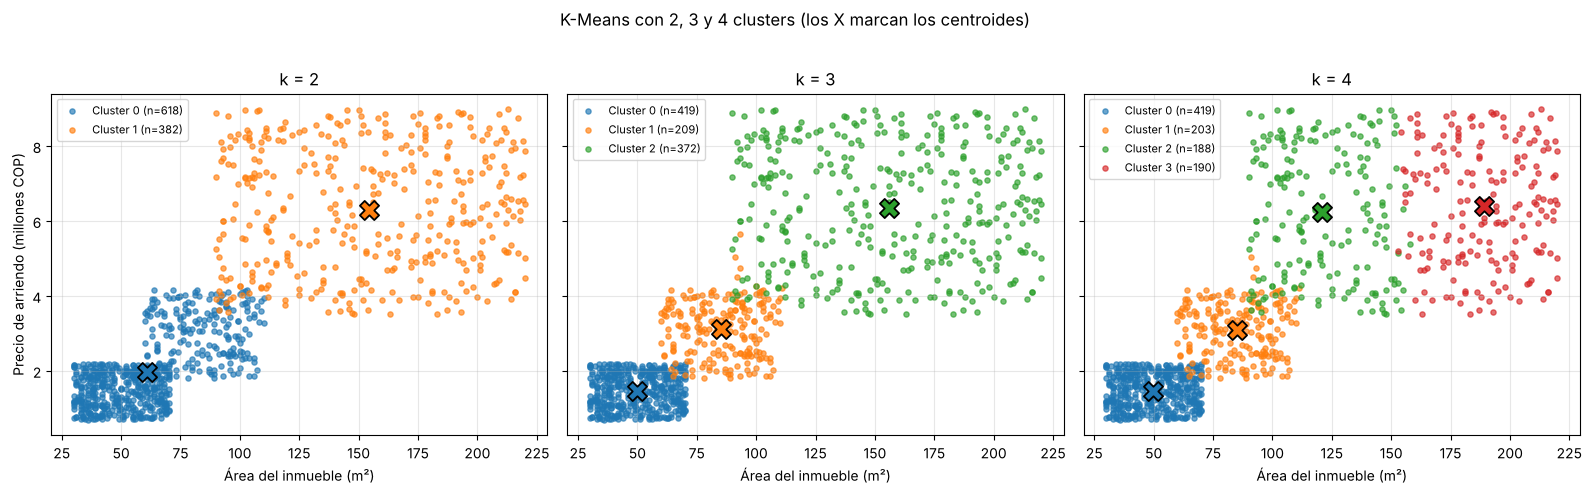

In [15]:
resultados = {}
for k in (2, 3, 4):
    modelo, etiquetas = ajustar_kmeans(k)
    resultados[k] = {"modelo": modelo, "etiquetas": etiquetas}
    df[f"cluster_k{k}"] = etiquetas

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for eje, k in zip(ejes, (2, 3, 4)):
    graficar_clusters(eje, resultados[k]["etiquetas"], k, f"k = {k}")
ejes[1].set_ylabel("")
ejes[2].set_ylabel("")
plt.suptitle("K-Means con 2, 3 y 4 clusters (los X marcan los centroides)", y=1.02)
plt.tight_layout(); plt.show()

In [16]:
for k in (2, 3, 4):
    print(f"===== k = {k} =====")
    print(perfil(f"cluster_k{k}").to_string())
    print()

===== k = 2 =====
            Inmuebles  Porcentaje  Area_m2  Habitaciones  Estrato  Precio_arriendo  Precio_por_m2
cluster_k2                                                                                       
0                 618        61.8     61.0           1.8      3.0        1984490.1        33305.1
1                 382        38.2    154.6           4.0      5.5        6300711.6        43657.0

===== k = 3 =====
            Inmuebles  Porcentaje  Area_m2  Habitaciones  Estrato  Precio_arriendo  Precio_por_m2
cluster_k3                                                                                       
0                 419        41.9     49.7           1.5      2.5        1469201.9        31406.4
1                 209        20.9     85.4           2.5      4.1        3130625.3        37694.7
2                 372        37.2    156.1           4.0      5.5        6353200.0        43607.7

===== k = 4 =====
            Inmuebles  Porcentaje  Area_m2  Habitaciones  Estr

In [17]:
filas = []
for k in (2, 3, 4):
    et = resultados[k]["etiquetas"]
    filas.append({
        "k": k,
        "Inercia": resultados[k]["modelo"].inertia_,
        "Silueta (↑)": silhouette_score(X_esc, et),
        "Davies-Bouldin (↓)": davies_bouldin_score(X_esc, et),
        "Calinski-Harabasz (↑)": calinski_harabasz_score(X_esc, et),
        "Grupo más pequeño (%)": np.bincount(et).min() / len(et) * 100,
    })
metricas = pd.DataFrame(filas).set_index("k").round(3)
metricas

,Inercia,Silueta (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Grupo más pequeño (%)
k,,,,,
2,1115.215,0.611,0.592,2581.578,38.2
3,767.227,0.482,0.716,2100.472,20.9
4,620.216,0.427,1.155,1809.188,18.8


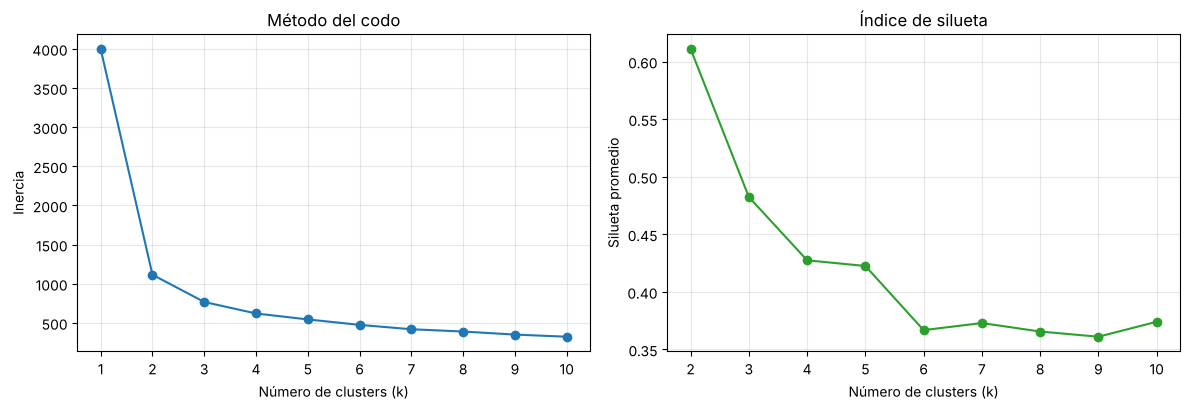

Inercia por k      : [4000.0, 1115.2, 767.2, 620.2, 544.3, 474.6, 418.9, 389.4, 350.7, 323.4]
Silueta por k (2..): {2: 0.611, 3: 0.482, 4: 0.427, 5: 0.422, 6: 0.367, 7: 0.373, 8: 0.366, 9: 0.361, 10: 0.374}
Reducción de inercia al pasar de k-1 a k: {2: '72.1 %', 3: '31.2 %', 4: '19.2 %', 5: '12.2 %', 6: '12.8 %', 7: '11.7 %'}


In [18]:
ks = range(1, 11)
inercias, siluetas = [], {}
for k in ks:
    m = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_esc)
    inercias.append(m.inertia_)
    if k >= 2:
        siluetas[k] = silhouette_score(X_esc, m.labels_)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
ejes[0].plot(list(ks), inercias, marker="o")
ejes[0].set(xlabel="Número de clusters (k)", ylabel="Inercia", title="Método del codo")
ejes[0].set_xticks(list(ks))
ejes[1].plot(list(siluetas), list(siluetas.values()), marker="o", color="tab:green")
ejes[1].set(xlabel="Número de clusters (k)", ylabel="Silueta promedio", title="Índice de silueta")
ejes[1].set_xticks(list(siluetas))
plt.tight_layout(); plt.show()

print("Inercia por k      :", [round(i, 1) for i in inercias])
print("Silueta por k (2..):", {k: round(v, 3) for k, v in siluetas.items()})
print("Reducción de inercia al pasar de k-1 a k:",
      {k: f"{(1 - inercias[k - 1] / inercias[k - 2]) * 100:.1f} %" for k in range(2, 8)})

**Lectura de las métricas.**

| k | Inercia | Silueta (↑) | Davies-Bouldin (↓) | Calinski-Harabasz (↑) | Grupo más pequeño |
|---|---|---|---|---|---|
| 2 | 1 115.2 | **0.611** | **0.592** | **2 581.6** | 38.2 % |
| 3 | 767.2 | 0.482 | 0.716 | 2 100.5 | 20.9 % |
| 4 | 620.2 | 0.427 | 1.155 | 1 809.2 | 18.8 % |

Las tres métricas internas favorecen *k* = 2, y las tres empeoran de forma continua al subir *k*. El método del
codo muestra que al pasar de 1 a 2 clusters la inercia cae 72 %, de 2 a 3 cae otro 31 %, de 3 a 4 un 19 %, y luego
cada paso aporta cerca de 12 %: el codo más fuerte está en 2, con un segundo recodo suave en 3.

Interpretando la silueta con la escala orientativa de Kaufman y Rousseeuw (1990), 0.51–0.70 indica una estructura
razonable y 0.26–0.50 una estructura débil. Con *k* = 2 hay una separación razonable (0.61); con *k* = 3 y 4 la
estructura es débil. La razón se ve en la gráfica de dispersión: los datos **no forman islas separadas por
espacios vacíos**; forman una escalera continua. La única brecha clara es la que separa los inmuebles pequeños y
baratos de los grandes y caros, y por eso *k* = 2 puntúa mejor. Los demás cortes son más "convencionales" (hay
que trazar la línea en algún sitio de una región continua).

### 5.1. Mirando de cerca el paso de 3 a 4 clusters

Al pasar de *k* = 3 a *k* = 4 cambia el segmento de mayor precio. Para entender cómo, comparo el precio por
metro cuadrado y el área de esos dos clusters nuevos.

In [19]:
premium = df[df["cluster_k3"] == 2]
print(f"Cluster premium con k = 3: {len(premium)} inmuebles")
print()
print("Con k = 4 se divide en dos grupos:")
t = df[df["cluster_k4"].isin([2, 3])].groupby("cluster_k4").agg(
    Inmuebles=("Inmueble", "count"), Area_m2=("Area_m2", "mean"), Habitaciones=("Habitaciones", "mean"),
    Estrato=("Estrato", "mean"), Precio_arriendo=("Precio_arriendo", "mean"), Precio_por_m2=("Precio_m2", "mean"),
).round(1)
print(t.to_string())
print()
print("Cruce k = 3 vs. k = 4 (filas = k3, columnas = k4):")
print(pd.crosstab(df["cluster_k3"], df["cluster_k4"]))

Cluster premium con k = 3: 372 inmuebles

Con k = 4 se divide en dos grupos:
            Inmuebles  Area_m2  Habitaciones  Estrato  Precio_arriendo  Precio_por_m2
cluster_k4                                                                           
2                 188    121.1           4.1      5.6        6243451.1        53124.3
3                 190    188.9           4.0      5.5        6392509.1        34189.5

Cruce k = 3 vs. k = 4 (filas = k3, columnas = k4):
cluster_k4    0    1    2    3
cluster_k3                    
0           419    0    0    0
1             0  203    6    0
2             0    0  182  190


Al pasar a 4 clusters los segmentos económico (419 inmuebles) y casi todo el intermedio se conservan; lo que
cambia es que el **premium se parte en dos** por tamaño:

| Segmento (k = 4) | Inmuebles | Área | Arriendo promedio | COP por m² |
|---|---|---|---|---|
| Premium compacto | 188 | 121.1 m² | 6 243 451 | **53 124** |
| Premium amplio | 190 | 188.9 m² | 6 392 509 | **34 190** |

Los dos grupos pagan casi el mismo arriendo (diferencia de 2 %), pero uno tiene un **55 % más de precio por metro
cuadrado**. Es una distinción real y comercialmente interesante (¿se está cobrando más por ubicación o acabados en
los compactos?), pero la gráfica muestra que no hay un vacío entre ambos: el corte cae hacia los 150 m² dentro de una
nube continua. Es un refinamiento útil, no una separación natural.

### Respuesta a la pregunta de la actividad: ¿cuál número de clusters es más útil?

**k = 3 para la operación comercial, con k = 4 como refinamiento opcional del segmento premium.**

- *k* = 2 tiene las mejores métricas, pero mezcla en un solo grupo (61.8 % del portafolio) inmuebles económicos
  de 1.47 millones con intermedios de 3.13 millones, que se arriendan a precios que duplican uno al otro. Sirve
  para decir "pequeño y barato" frente a "grande y caro", pero no permite diseñar acciones distintas.
- *k* = 3 recupera los tres niveles que describe el enunciado (económico, intermedio, premium), cada uno con
  un perfil nítido y un tamaño relevante (el menor tiene 20.9 % del portafolio), y queda en la zona del codo
  donde la inercia todavía cae 31 %.
- *k* = 4 solo añade una distinción dentro del premium; la silueta baja a 0.43 y el índice de Davies-Bouldin sube
  a 1.16 (grupos más solapados).

---
## 6. Perfil comercial de los segmentos (k = 3)

Una vez elegido *k*, hay que volver al negocio: cada segmento debe poder describirse en una frase y dar pie a una
acción comercial distinta. Las gráficas de caja muestran cómo se reparten las variables dentro de cada grupo.

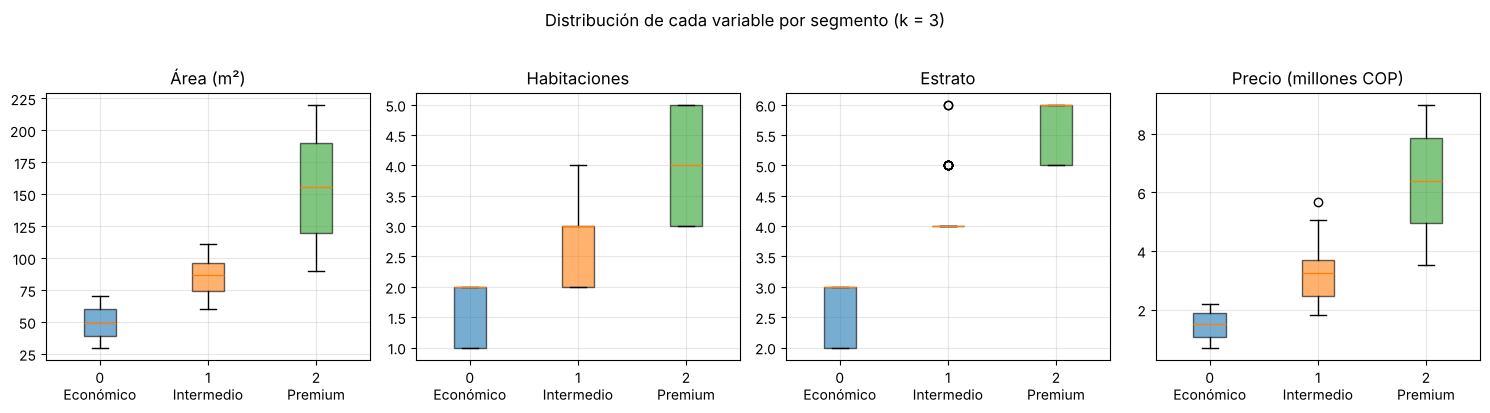

In [20]:
fig, ejes = plt.subplots(1, 4, figsize=(15, 4))
for eje, col, titulo in zip(ejes, VARIABLES, ["Área (m²)", "Habitaciones", "Estrato", "Precio (millones COP)"]):
    datos = [df.loc[df["cluster"] == c, col] / (1e6 if col == "Precio_arriendo" else 1) for c in range(3)]
    caja = eje.boxplot(datos, tick_labels=["0\nEconómico", "1\nIntermedio", "2\nPremium"], patch_artist=True)
    for parche, color in zip(caja["boxes"], COLORES):
        parche.set_facecolor(color); parche.set_alpha(0.6)
    eje.set_title(titulo)
plt.suptitle("Distribución de cada variable por segmento (k = 3)", y=1.02)
plt.tight_layout(); plt.show()

In [21]:
print("Distribución de los segmentos por localidad y por tipo de inmueble (% dentro de cada cluster):")
print()
print((pd.crosstab(df["cluster"], df["Localidad"], normalize="index") * 100).round(1).to_string())
print()
print((pd.crosstab(df["cluster"], df["Tipo_inmueble"], normalize="index") * 100).round(1).to_string())

Distribución de los segmentos por localidad y por tipo de inmueble (% dentro de cada cluster):

Localidad  Chapinero  Suba  Usaquén
cluster                            
0               34.8  36.3     28.9
1               34.4  31.6     34.0
2               30.9  31.2     37.9

Tipo_inmueble  ApartaEstudio  Apto  Casa
cluster                                 
0                       28.9  36.3  34.8
1                       34.0  31.6  34.4
2                       37.9  31.2  30.9


In [22]:
from scipy.stats import chi2_contingency

# ¿Cuánto del recaudo mensual aporta cada segmento?
ingresos = df.groupby("cluster")["Precio_arriendo"].sum()
t = pd.DataFrame({
    "Inmuebles (%)": df["cluster"].value_counts(normalize=True).sort_index() * 100,
    "Recaudo mensual (millones COP)": ingresos / 1e6,
    "Recaudo (%)": ingresos / ingresos.sum() * 100,
}).round(1)
print(t.to_string())
print()

# ¿Los segmentos dependen de la localidad? Prueba chi-cuadrado de independencia
for var in ["Localidad"]:
    tabla = pd.crosstab(df["cluster"], df[var])
    chi2, p, gl, _ = chi2_contingency(tabla)
    v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    print(f"Cluster vs. {var}: chi2 = {chi2:.2f}, gl = {gl}, p = {p:.3f}, V de Cramér = {v_cramer:.3f}")

         Inmuebles (%)  Recaudo mensual (millones COP)  Recaudo (%)
cluster                                                            
0                 41.9                           615.6         16.9
1                 20.9                           654.3         18.0
2                 37.2                          2363.4         65.0

Cluster vs. Localidad: chi2 = 7.67, gl = 4, p = 0.105, V de Cramér = 0.062


Dos resultados útiles para el negocio:

- **Concentración del recaudo.** El segmento premium es el 37.2 % de los inmuebles pero genera cerca del 65 % del
  arriendo mensual del portafolio; el económico, que es el 41.9 % de los inmuebles, aporta apenas el 17 %. Perder
  un inmueble premium "cuesta" unas cuatro veces más que perder uno económico.
- **La localidad no distingue los segmentos.** La prueba chi-cuadrado de independencia **no encuentra
  dependencia significativa** (χ² = 7.67, 4 grados de libertad, p = 0.105; V de Cramér = 0.062, un efecto
  prácticamente nulo). Las diferencias que se ven en la tabla (por ejemplo, 37.9 % de premium en Usaquén frente a
  30.9 % en Chapinero) son compatibles con el azar, y los tres segmentos están presentes en las tres localidades
  en proporciones parecidas. En este dataset, **lo que separa los segmentos es el tamaño y el valor del inmueble,
  no dónde está**.

---
## 7. Aplicación: recomendar inmuebles con el modelo

La pregunta 11 del enunciado pide explicar cómo K-Means puede mejorar las recomendaciones a los clientes. Una
demostración: llega un cliente que busca un inmueble de unos 80 m², 3 habitaciones, estrato 4 y presupuesto de
3 millones. Se le **asigna a un segmento** con `predict` y se le recomiendan los inmuebles de ese segmento que
más se parecen a lo que pidió.

In [23]:
deseado = pd.DataFrame([{"Area_m2": 80, "Habitaciones": 3, "Estrato": 4, "Precio_arriendo": 3_000_000}])
deseado_esc = scaler.transform(deseado[VARIABLES])

# Segmento al que pertenece el perfil buscado (con la numeración ordenada por precio)
etiqueta_interna = modelo3.predict(deseado_esc)[0]
mapa = pd.Series(df["cluster"].values).groupby(modelo3.labels_).first()
segmento = int(mapa[etiqueta_interna])
nombres = {0: "Económico", 1: "Intermedio", 2: "Premium"}
print(f"El perfil buscado pertenece al segmento {segmento} ({nombres[segmento]}).")

# Recomendar los 5 inmuebles de ese segmento más cercanos a lo que pidió el cliente
candidatos = df[df["cluster"] == segmento].copy()
cand_esc = scaler.transform(candidatos[VARIABLES])
candidatos["Distancia"] = np.linalg.norm(cand_esc - deseado_esc, axis=1)
print()
print("Cinco inmuebles recomendados:")
candidatos.nsmallest(5, "Distancia")[["Inmueble", "Area_m2", "Habitaciones", "Estrato", "Precio_arriendo", "Localidad", "Distancia"]].round(2)

El perfil buscado pertenece al segmento 1 (Intermedio).

Cinco inmuebles recomendados:


,Inmueble,Area_m2,Habitaciones,Estrato,Precio_arriendo,Localidad,Distancia
438,I439,79,3,4,3002867,Suba,0.02
275,I276,83,3,4,3061402,Usaquén,0.06
411,I412,78,3,4,3125218,Suba,0.06
5,I6,76,3,4,2836207,Usaquén,0.10
892,I893,82,3,4,2752413,Chapinero,0.11


---
## 8. Respuestas a las preguntas del enunciado

**1. ¿Por qué este ejercicio corresponde a aprendizaje no supervisado?**
Porque los datos **no traen una etiqueta o respuesta** que el algoritmo deba aprender a predecir: nadie le dijo
a la inmobiliaria a qué segmento pertenece cada inmueble. K-Means recibe solo las características (área,
habitaciones, estrato, precio) y descubre los grupos por sí solo, a partir de la similitud entre los registros.

**2. ¿Cuál es la diferencia entre clasificación y clustering?**
La **clasificación** es supervisada: aprende de ejemplos con etiqueta conocida (por ejemplo, "este inmueble se
arrendó / no se arrendó") para predecir la etiqueta de ejemplos nuevos, y se evalúa comparando con la etiqueta
real (exactitud, F1). El **clustering** es no supervisado: *crea* los grupos a partir de los datos, sin etiqueta
previa, y no hay una "respuesta correcta" con la cual compararlos; el analista es quien interpreta y nombra los
grupos (económico, intermedio, premium) y los valida con métricas internas (inercia, silueta) y con su utilidad.

**3. ¿Qué representa un cluster en este caso?**
Un **segmento comercial**: un conjunto de inmuebles parecidos entre sí en tamaño, número de habitaciones, estrato
y precio, y distintos de los de otros segmentos. Su centroide es el "inmueble típico" del grupo (por ejemplo, el
del cluster 2: 156 m², 4 habitaciones, estrato 5.5 y 6.35 millones de arriendo).

**4. ¿Por qué el precio de arriendo puede influir mucho en el resultado?**
Por dos razones. La primera es la **escala**: K-Means usa distancias y el precio se mide en millones, mientras que
las demás variables se miden en decenas o en unidades; sin escalar, el precio aporta el 100 % de la varianza y los
grupos resultan idénticos a los de agrupar solo por precio (ARI = 1.000; 228 inmuebles cambian de grupo al
escalar). La segunda es la **redundancia**: área, habitaciones y estrato están correlacionados con el precio
(0.78–0.84), así que incluso escaladas le repiten la misma información y refuerzan su peso.

**5. ¿Cuántos clusters se definieron?**
Tres en el modelo principal (`n_clusters=3`, el valor del script del docente). Además se evaluaron dos y cuatro,
como pide la actividad, y se concluyó que k = 3 es el más útil.

**6. ¿Qué características tiene cada cluster?**

| Cluster | Inmuebles | Área | Hab. | Estrato | Arriendo | COP/m² | Recaudo |
|---|---|---|---|---|---|---|---|
| **0 — Económico** | 419 (41.9 %) | 49.7 m² | 1.5 | 2.5 | 1.47 M | 31 406 | 17 % |
| **1 — Intermedio** | 209 (20.9 %) | 85.4 m² | 2.5 | 4.1 | 3.13 M | 37 695 | 18 % |
| **2 — Premium** | 372 (37.2 %) | 156.1 m² | 4.0 | 5.5 | 6.35 M | 43 608 | 65 % |

**7. ¿Qué estrategia comercial se podría aplicar para cada grupo?**

| Segmento | Cliente probable | Estrategia |
|---|---|---|
| **Económico** | Estudiantes, parejas jóvenes, primer arriendo | Estrategia de **volumen y rotación**: publicar en portales masivos, trámites ágiles y requisitos simples, precios competitivos, contratos de 12 meses con incentivos por pago puntual, y vender servicios complementarios como el seguro de arriendo. |
| **Intermedio** | Familias pequeñas, profesionales | Resaltar la **relación entre precio y valor** (área, estrato, cercanía a servicios), ofrecer flexibilidad (mascotas, plazos), y fidelizar para que al crecer la familia pasen al segmento siguiente sin salir de la inmobiliaria. |
| **Premium** | Familias grandes, ejecutivos, expatriados | **Atención personalizada** con un asesor dedicado, fotografía profesional y recorridos virtuales, publicación selectiva en canales de alto perfil, contratos largos con administración y mantenimiento incluidos. Como aporta cerca del 65 % del recaudo, merece las acciones de retención más cuidadosas. |

**8. ¿Cómo podría usar esta segmentación una inmobiliaria?**
Para **fijar y revisar precios** (comparar un inmueble con el precio por m² típico de su segmento y detectar los
que están mal valorados), **asignar asesores y presupuesto de marketing** según el aporte de cada segmento,
**planear el portafolio** (la dependencia del 65 % del recaudo en un solo segmento es un riesgo de
concentración), **dirigir campañas** a cada perfil de cliente y **medir resultados por segmento** (tiempo vacío,
rotación, morosidad).

**9. ¿Qué pasaría si utilizamos `n_clusters=2`?**
Se obtienen dos grupos: uno de 618 inmuebles (61.8 %; 61 m², 1.8 habitaciones, estrato 3.0, 1.98 millones) y otro
de 382 (38.2 %; 154.6 m², 4.0 habitaciones, estrato 5.5, 6.30 millones). Tiene las mejores métricas (silueta
0.611) porque separa la única brecha clara de los datos, pero es una segmentación demasiado gruesa: junta
inmuebles económicos e intermedios con precios que difieren casi al doble y no permite estrategias diferenciadas.

**10. ¿Qué pasaría si utilizamos `n_clusters=4`?**
El económico (419) y el intermedio (203) casi no cambian, y el premium se divide en **premium compacto** (188
inmuebles, 121 m², 53 124 COP/m²) y **premium amplio** (190 inmuebles, 189 m², 34 190 COP/m²), con arriendos casi
iguales (6.24 y 6.39 millones). La silueta cae a 0.427 y Davies-Bouldin sube a 1.155: los grupos nuevos no están
separados por un vacío en los datos. Es útil solo si la inmobiliaria quiere diferenciar el premium por precio por
metro cuadrado.

**11. Explique cómo K-Means puede ayudar a una inmobiliaria a mejorar las recomendaciones para los clientes.**
El modelo permite pasar de "buscar entre mil inmuebles" a "buscar dentro del segmento correcto". Cuando llega un
cliente se convierte su necesidad (área, habitaciones, estrato, presupuesto) en un punto, el modelo lo asigna a un
segmento con `predict`, y se le recomiendan los inmuebles de ese segmento más cercanos a su perfil (sección 7:
para 80 m², 3 habitaciones, estrato 4 y 3 millones, el modelo lo ubica en el segmento intermedio y propone cinco
inmuebles muy próximos a lo pedido). Además, si el cliente duda de su presupuesto, los centroides de los segmentos
vecinos sirven para mostrarle qué obtendría pagando un poco más o un poco menos.

---
## 9. Conclusiones

1. **K-Means encontró tres segmentos útiles** (económico, intermedio y premium) en los 1 000 inmuebles, los mismos
   que describe el ejemplo del docente con 12 registros.
2. **Escalar los datos no es opcional**: sin escalar, el modelo agrupa exclusivamente por precio y descarta el
   resto de información.
3. **El número de clusters no lo decide el algoritmo.** Las métricas internas favorecen k = 2, pero la utilidad
   comercial y el codo respaldan k = 3; k = 4 solo refina el premium. Las métricas orientan, la decisión es de
   negocio.
4. **La estructura es una escalera continua, no islas separadas**, y por eso las siluetas de k = 3 y 4 son
   modestas. Los grupos son útiles como convención de gestión, no como "especies" naturales.
5. **El dataset tiene redundancias** que importan: área, habitaciones, estrato y precio miden casi lo mismo;
   baños y antigüedad no se relacionan con nada; localidad y tipo son idénticos; y `Estrato` aparece duplicado con
   una segunda columna sin información. En el notebook 2 se analiza qué hace PCA con esa redundancia.